## Phase1

In [1]:
import sys

print(sys.executable)

/media/umair/Data/PortfolioProjects/research-agent/.venv/bin/python


In [2]:
import os
from dotenv import load_dotenv
from IPython.display import Image, display
from langgraph.graph import START, END, StateGraph
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage
from langchain_google_genai import ChatGoogleGenerativeAI
load_dotenv()
model = ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite",
    google_api_key=os.environ.get("GOOGLE_API_KEY"),
)

In [3]:
from typing_extensions import TypedDict
from pydantic import BaseModel

class Analyst(BaseModel):
    name:str
    role:str
    focus:str
    description:str
    @property
    def persona(self) -> str:
        return f"Name: {self.name}\nRole: {self.role}\nDescription: {self.description}\n"
class GenerateAnalystsState(TypedDict):
    topic:str
    max_analysts:int
    analysts:list[Analyst]
    human_analyst_feedback:str
class Percpective(BaseModel):
    analysts: list[Analyst]

In [4]:

analyst_instructions="""You are tasked with creating a set of AI analyst personas. Follow these instructions carefully:

1. First, review the research topic:
{topic}
        
2. Examine any editorial feedback that has been optionally provided to guide creation of the analysts: 
        
{human_analyst_feedback}
    
3. Determine the most interesting themes based upon documents and / or feedback above.
                    
4. Pick the top {max_analysts} themes.

5. Assign one analyst to each theme."""



In [5]:
def create_analyst(state:GenerateAnalystsState):
    topic=state['topic']
    max_analyst=state['max_analysts']
    human_feedback=state.get('human_analyst_feedback', '')

    structure_llm = model.with_structured_output(Percpective)

    system_message = analyst_instructions.format(topic=topic,human_analyst_feedback=human_feedback,max_analysts=max_analyst)
    analysts = structure_llm.invoke([SystemMessage(content=system_message)]+[HumanMessage(content="Generate the set of analysts.")])
    return ({"analysts":analysts.analysts})

def human_feedback(state: GenerateAnalystsState):
    """ No-op node that should be interrupted on """
    pass
def condition_should_continue(state: GenerateAnalystsState):
    """ Return the next node to execute """
    human_feedback = state.get('human_analyst_feedback',None)
    if human_feedback:
        return "create_analyst"
    
    return END

In [6]:
import operator
from typing import Annotated
from pydantic import Field
from langgraph.graph import MessagesState
class InterviewerState(MessagesState):
    max_turn:int
    analyst: Analyst
    context:Annotated[list, operator.add]
    interviewer:str
    sections:list
class SearchQuerry(BaseModel):
    search_query:str = Field(None, description="Search query for retrieval.")

In [7]:
question_instructions = """You are an analyst tasked with interviewing an expert to learn about a specific topic. 

Your goal is boil down to interesting and specific insights related to your topic.

1. Interesting: Insights that people will find surprising or non-obvious.
        
2. Specific: Insights that avoid generalities and include specific examples from the expert.

Here is your topic of focus and set of goals: {goals}
        
Begin by introducing yourself using a name that fits your persona, and then ask your question.

Continue to ask questions to drill down and refine your understanding of the topic.
        
When you are satisfied with your understanding, complete the interview with: "Thank you so much for your help!"

Remember to stay in character throughout your response, reflecting the persona and goals provided to you."""
def generate_question(state:InterviewerState):
    analyst = state['analyst']
    message = state['messages']
    system_message= question_instructions.format(goals = analyst.persona)
    question = model.invoke([SystemMessage(content=system_message)]+message+[HumanMessage(content="Generate a question according to the instruction.")])
    return {"messages":[question]}




In [8]:
from langchain_tavily import TavilySearch
from langchain_community.document_loaders import WikipediaLoader
import wikipedia.wikipedia as wiki_api

wiki_api.USER_AGENT = (
    "ResearchAgent/1.0 (educational project; contact: your-email@example.com)"
)
tavily_search = TavilySearch(max_results=3)
search_instructions = SystemMessage(content=f"""You will be given a conversation between an analyst and an expert. 

Your goal is to generate a well-structured query for use in retrieval and / or web-search related to the conversation.
        
First, analyze the full conversation.

Pay particular attention to the final question posed by the analyst.

Convert this final question into a well-structured web search query""")
def search_web(state:InterviewerState):
    
    message = state['messages']
    structure_llm = model.with_structured_output(SearchQuerry)
    search = structure_llm.invoke([search_instructions]+message    + [HumanMessage(content="Generate a search query based on the conversation.")])
    data = tavily_search.invoke({"query": search.search_query})
    search_docs = data.get("results", data)
    

     # Format
    formatted_search_docs = "\n\n---\n\n".join(
        [
            f'<Document href="{doc["url"]}"/>\n{doc["content"]}\n</Document>'
            for doc in search_docs
        ]
    )
    return {"context":[formatted_search_docs]}

def search_wikki(state:InterviewerState):
    message = state['messages']
    structure_llm = model.with_structured_output(SearchQuerry)
    search = structure_llm.invoke(
    [search_instructions]
    + message
    + [HumanMessage(content="Generate a search query based on the conversation.")]
)
    # Search
    search_docs = WikipediaLoader(query=search.search_query, 
                                  load_max_docs=2).load()

     # Format
    formatted_search_docs = "\n\n---\n\n".join(
        [
            f'<Document source="{doc.metadata["source"]}" page="{doc.metadata.get("page", "")}"/>\n{doc.page_content}\n</Document>'
            for doc in search_docs
        ]
    )
    return {"context":[formatted_search_docs]}



/tmp/ipykernel_57118/15220951.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WikipediaLoader


In [9]:

from langchain_core.messages import get_buffer_string

answer_instructions = """You are an expert being interviewed by an analyst.

Here is analyst area of focus: {goals}. 
        
You goal is to answer a question posed by the interviewer.

To answer question, use this context:
        
{context}

When answering questions, follow these guidelines:
        
1. Use only the information provided in the context. 
        
2. Do not introduce external information or make assumptions beyond what is explicitly stated in the context.

3. The context contain sources at the topic of each individual document.

4. Include these sources your answer next to any relevant statements. For example, for source # 1 use [1]. 

5. List your sources in order at the bottom of your answer. [1] Source 1, [2] Source 2, etc
        
6. If the source is: <Document source="assistant/docs/llama3_1.pdf" page="7"/>' then just list: 
        
[1] assistant/docs/llama3_1.pdf, page 7 
        
And skip the addition of the brackets as well as the Document source preamble in your citation."""
def answer_question(state:InterviewerState):
    """ Node to answer a question """

    analyst = state['analyst']
    messages = state['messages']
    context = state['context']
    system_message=answer_instructions.format(goals=analyst.persona,context=context)
    answer = model.invoke([SystemMessage(system_message)]+messages+[HumanMessage(content="Answer The question based on context given to you")]) 
    answer.name = "expert"
    return {"messages":[answer]}

def save_interview(state:InterviewerState):
    """Save Interview"""
    message = state['messages']
    message = get_buffer_string(message)
    return {"interviwe":message}

def route_message(state:InterviewerState,name:str ="expert"):
    """Route Message"""
    message =state['messages']
    max_num = state.get("max_turn",2)
    curr_num=len([m  for m in message if isinstance(m,AIMessage) and name==m.name])
    if(curr_num>=max_num):
        return "interview_save"
    lastquestion=message[-2]
    if "Thank you so much for your help" in lastquestion.content:
        return "interview_save"
    return "ask_question"
section_writer_instructions = """You are an expert technical writer. 
            
Your task is to create a short, easily digestible section of a report based on a set of source documents.

1. Analyze the content of the source documents: 
- The name of each source document is at the start of the document, with the <Document tag.
        
2. Create a report structure using markdown formatting:
- Use ## for the section title
- Use ### for sub-section headers
        
3. Write the report following this structure:
a. Title (## header)
b. Summary (### header)
c. Sources (### header)

4. Make your title engaging based upon the focus area of the analyst: 
{focus}

5. For the summary section:
- Set up summary with general background / context related to the focus area of the analyst
- Emphasize what is novel, interesting, or surprising about insights gathered from the interview
- Create a numbered list of source documents, as you use them
- Do not mention the names of interviewers or experts
- Aim for approximately 400 words maximum
- Use numbered sources in your report (e.g., [1], [2]) based on information from source documents
        
6. In the Sources section:
- Include all sources used in your report
- Provide full links to relevant websites or specific document paths
- Separate each source by a newline. Use two spaces at the end of each line to create a newline in Markdown.
- It will look like:

### Sources
[1] Link or Document name
[2] Link or Document name

7. Be sure to combine sources. For example this is not correct:

[3] https://ai.meta.com/blog/meta-llama-3-1/
[4] https://ai.meta.com/blog/meta-llama-3-1/

There should be no redundant sources. It should simply be:

[3] https://ai.meta.com/blog/meta-llama-3-1/
        
8. Final review:
- Ensure the report follows the required structure
- Include no preamble before the title of the report
- Check that all guidelines have been followed"""
def write_section(state:InterviewerState):
    """Node to write section answer to a question"""
    analyst = state['analyst']
    context=state['context']
    system_message = section_writer_instructions.format(focus=analyst.description)
    sec = model.invoke([SystemMessage(content=system_message)]+[HumanMessage(content=f"Use this source to write your section: {context}")])
    return {"sections": [sec.content[0]["text"]]}

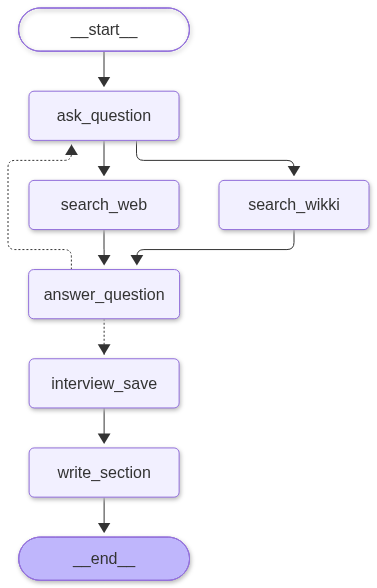

In [10]:
Interviewer=StateGraph(InterviewerState)
Interviewer.add_node("interview_save",save_interview)
Interviewer.add_node("ask_question",generate_question)
Interviewer.add_node("write_section",write_section)
Interviewer.add_node("search_web",search_web)
Interviewer.add_node("search_wikki",search_wikki)
Interviewer.add_node("answer_question",answer_question)


Interviewer.add_edge(START,"ask_question")
Interviewer.add_edge("ask_question","search_web")
Interviewer.add_edge("ask_question","search_wikki")
Interviewer.add_edge("search_web","answer_question")
Interviewer.add_edge("search_wikki","answer_question")
Interviewer.add_conditional_edges("answer_question",route_message,["ask_question","interview_save"])
Interviewer.add_edge("interview_save","write_section")
Interviewer.add_edge("write_section",END)

memory = MemorySaver()
interview_graph = Interviewer.compile(checkpointer=memory).with_config(run_name="Conduct Interviews")

# View
display(Image(interview_graph.get_graph().draw_mermaid_png()))


In [11]:
class ResearchGraphState(TypedDict):
    topic:str
    max_analysts:int
    analysts:list[Analyst]
    human_analyst_feedback:str
    sections: Annotated[list, operator.add] 
    introduction:str
    conclusion:str
    content:str
    final_report:str

In [12]:
from langgraph.types import Send
def initailized_agents(state:ResearchGraphState):
    human_feedback = state.get("human_analyst_feedback")
    if human_feedback:
        return "create_analyst"
    else:
        topic = state['topic']
        return [Send("conduct_interview",{"analyst":analyst, "messages": [HumanMessage(
                                                       content=f"So you said you were writing an article on {topic}?"
                                                   )]})for analyst in state["analysts"]]

report_writer_instructions = """You are a technical writer creating a report on this overall topic: 

{topic}
    
You have a team of analysts. Each analyst has done two things: 

1. They conducted an interview with an expert on a specific sub-topic.
2. They write up their finding into a memo.

Your task: 

1. You will be given a collection of memos from your analysts.
2. Think carefully about the insights from each memo.
3. Consolidate these into a crisp overall summary that ties together the central ideas from all of the memos. 
4. Summarize the central points in each memo into a cohesive single narrative.

To format your report:
 
1. Use markdown formatting. 
2. Include no pre-amble for the report.
3. Use no sub-heading. 
4. Start your report with a single title header: ## Insights
5. Do not mention any analyst names in your report.
6. Preserve any citations in the memos, which will be annotated in brackets, for example [1] or [2].
7. Create a final, consolidated list of sources and add to a Sources section with the `## Sources` header.
8. List your sources in order and do not repeat.

[1] Source 1
[2] Source 2

Here are the memos from your analysts to build your report from: 

{context}"""
def write_report(state:ResearchGraphState):
    topic=state['topic']

    formatted_str_sections = "\n\n".join([f"{section}" for section in state['sections']])
    instruction = report_writer_instructions.format(topic=topic,context=formatted_str_sections)
    content=model.invoke([SystemMessage(content=instruction)]+[HumanMessage(content=f"Write the report introduction")])
    return {"content": content.content}

In [13]:
intro_conclusion_instructions = """You are a technical writer finishing a report on {topic}

You will be given all of the sections of the report.

You job is to write a crisp and compelling introduction or conclusion section.

The user will instruct you whether to write the introduction or conclusion.

Include no pre-amble for either section.

Target around 100 words, crisply previewing (for introduction) or recapping (for conclusion) all of the sections of the report.

Use markdown formatting. 

For your introduction, create a compelling title and use the # header for the title.

For your introduction, use ## Introduction as the section header. 

For your conclusion, use ## Conclusion as the section header.

Here are the sections to reflect on for writing: {formatted_str_sections}"""

def write_introduction(state: ResearchGraphState):
    # Full set of sections
    sections = state["sections"]
    topic = state["topic"]

    # Concat all sections together
    formatted_str_sections = "\n\n".join([f"{section}" for section in sections])
    
    # Summarize the sections into a final report
    
    instructions = intro_conclusion_instructions.format(topic=topic, formatted_str_sections=formatted_str_sections)    
    intro = model.invoke([instructions]+[HumanMessage(content=f"Write the report introduction")]) 
    return {"introduction": intro.content}

def write_conclusion(state: ResearchGraphState):
    # Full set of sections
    sections = state["sections"]
    topic = state["topic"]

    # Concat all sections together
    formatted_str_sections = "\n\n".join([f"{section}" for section in sections])
    
    # Summarize the sections into a final report
    
    instructions = intro_conclusion_instructions.format(topic=topic, formatted_str_sections=formatted_str_sections)    
    conclusion = model.invoke([instructions]+[HumanMessage(content=f"Write the report conclusion")]) 
    return {"conclusion": conclusion.content}

def finalize_report(state: ResearchGraphState):
    """
    The reduce step: gathers all report sections,
    combines them, and adds the introduction and conclusion.
    """

    # Helper function to convert Gemini output into plain text
    def extract_text(value):
        if isinstance(value, list):
            return "\n\n".join(
                item["text"] if isinstance(item, dict) and "text" in item
                else str(item)
                for item in value
            )

        return value

    # Convert all three outputs into strings
    content = extract_text(state["content"])
    introduction = extract_text(state["introduction"])
    conclusion = extract_text(state["conclusion"])

    # Remove the Insights heading
    if content.startswith("## Insights"):
        content = content.removeprefix("## Insights").lstrip()

    # Extract sources from the report
    if "\n## Sources\n" in content:
        content, sources = content.split("\n## Sources\n", 1)
    else:
        sources = None

    # Combine introduction, content, and conclusion
    final_report = (
        introduction
        + "\n\n---\n\n"
        + content
        + "\n\n---\n\n"
        + conclusion
    )

    # Append sources if available
    if sources is not None:
        final_report += "\n\n## Sources\n" + sources

    return {"final_report": final_report}

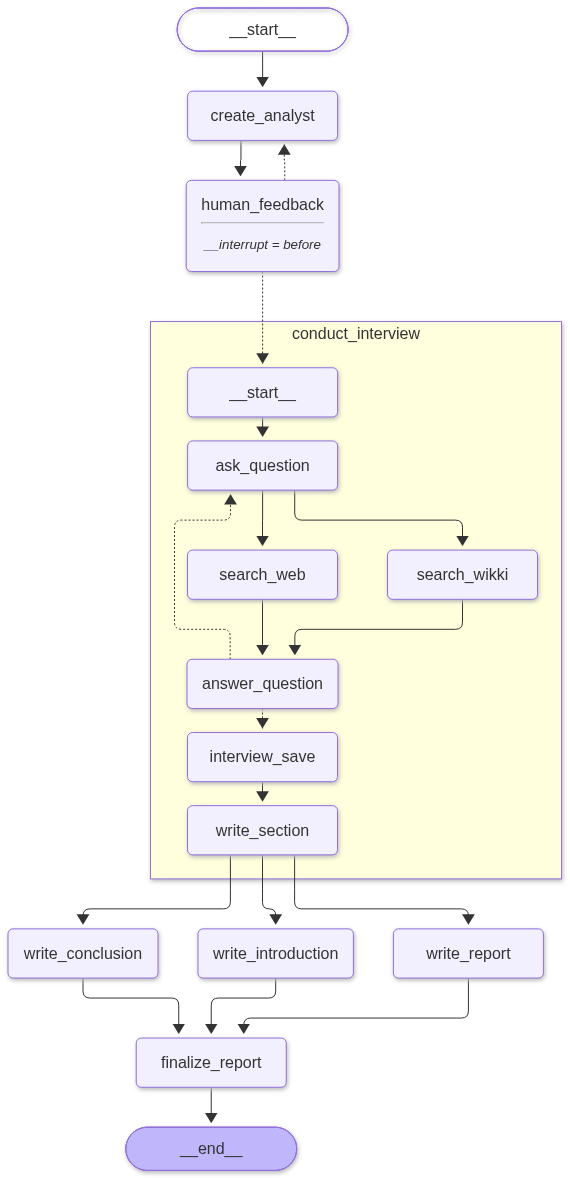

In [14]:
final_builder=StateGraph(ResearchGraphState)
final_builder.add_node("create_analyst",create_analyst)
final_builder.add_node("human_feedback",human_feedback)
final_builder.add_node("conduct_interview",Interviewer.compile())
final_builder.add_node("write_report",write_report)
final_builder.add_node("write_introduction",write_introduction)
final_builder.add_node("write_conclusion",write_conclusion)
final_builder.add_node("finalize_report",finalize_report)

final_builder.add_edge(START,"create_analyst")
final_builder.add_edge("create_analyst","human_feedback")
final_builder.add_conditional_edges("human_feedback",initailized_agents,["create_analyst","conduct_interview"])
final_builder.add_edge("conduct_interview", "write_report")
final_builder.add_edge("conduct_interview", "write_introduction")
final_builder.add_edge("conduct_interview", "write_conclusion")
final_builder.add_edge(["write_conclusion", "write_report", "write_introduction"], "finalize_report")
final_builder.add_edge("finalize_report", END)


memory = MemorySaver()
graph = final_builder.compile(interrupt_before=['human_feedback'], checkpointer=memory)
display(Image(graph.get_graph(xray=1).draw_mermaid_png()))


In [15]:
max_analysts = 3 
topic = "AI application in healthcare"
thread = {"configurable": {"thread_id": "1"}}
for event in graph.stream({"topic":topic,"max_analysts":max_analysts},thread,stream_mode="values"):
        
    analysts = event.get('analysts', '')
    if analysts:
        for analyst in analysts:
            print(f"Name: {analyst.name}")
            print(f"Role: {analyst.role}")
            print(f"Description: {analyst.description}")
            print("-" * 50)  

Name: Dr. Elena Vance
Role: Clinical Informatics Specialist
Description: Focused on how AI-driven predictive modeling and medical imaging integration can reduce clinician burnout and improve patient diagnostic outcomes.
--------------------------------------------------
Name: Marcus Thorne
Role: Healthcare Ethics & Policy Analyst
Description: Expert in assessing the regulatory landscape, patient data sovereignty, and the mitigation of systemic biases in AI-driven healthcare delivery systems.
--------------------------------------------------
Name: Sarah Jenkins
Role: Health Systems Economist
Description: Specializes in the financial implications of AI integration in large-scale healthcare providers, focusing on return-on-investment and long-term sustainability of AI health infrastructure.
--------------------------------------------------


In [16]:
# We now update the state as if we are the human_feedback node
graph.update_state(thread, {"human_analyst_feedback": 
                                "Add in the Hospital Senior Doctor as well"}, as_node="human_feedback")

Deserializing unregistered type __main__.Analyst from checkpoint. This will be blocked in a future version. Set LANGGRAPH_STRICT_MSGPACK=true to block now, or add to allowed_msgpack_modules to allow explicitly: [('__main__', 'Analyst')]


{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1df6f1-e83c-63a4-8002-5db79ea18711'}}

In [17]:
# Check
for event in graph.stream(None, thread, stream_mode="values"):
    analysts = event.get('analysts', '')
    if analysts:
        for analyst in analysts:
            print(f"Name: {analyst.name}")
            print(f"Role: {analyst.role}")
            print(f"Description: {analyst.description}")
            print("-" * 50)  

Name: Dr. Elena Vance
Role: Clinical Informatics Specialist
Description: Focused on how AI-driven predictive modeling and medical imaging integration can reduce clinician burnout and improve patient diagnostic outcomes.
--------------------------------------------------
Name: Marcus Thorne
Role: Healthcare Ethics & Policy Analyst
Description: Expert in assessing the regulatory landscape, patient data sovereignty, and the mitigation of systemic biases in AI-driven healthcare delivery systems.
--------------------------------------------------
Name: Sarah Jenkins
Role: Health Systems Economist
Description: Specializes in the financial implications of AI integration in large-scale healthcare providers, focusing on return-on-investment and long-term sustainability of AI health infrastructure.
--------------------------------------------------
Name: Dr. Elena Vance
Role: Hospital Senior Doctor
Description: A veteran physician evaluating how AI diagnostic tools integrate into daily patient c

In [18]:
# Confirm we are happy
graph.update_state(thread, {"human_analyst_feedback": 
                            None}, as_node="human_feedback")

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1df6f2-3291-6833-8004-380946d84702'}}

In [19]:
# Continue
for event in graph.stream(None, thread, stream_mode="updates"):
    print("--Node--")
    node_name = next(iter(event.keys()))
    print(node_name)

--Node--
conduct_interview
--Node--
conduct_interview
--Node--
conduct_interview
--Node--
write_conclusion
--Node--
write_introduction
--Node--
write_report
--Node--
finalize_report


In [20]:
from IPython.display import Markdown
final_state = graph.get_state(thread)
report = final_state.values.get('final_report')
Markdown(report)

# Preserving the Human Connection: Navigating AI Integration in Clinical Practice

## Introduction

The rapid integration of Artificial Intelligence into healthcare marks a transformative shift, offering unprecedented opportunities to enhance diagnostic precision and streamline hospital operations. Yet, this evolution is shadowed by critical challenges: the threat of algorithmic bias, the "black box" nature of complex models, and the potential erosion of the essential doctor-patient relationship. As medical systems transition from isolated pilots to core infrastructure, success depends on moving beyond simple performance metrics. This report examines how clinicians, administrators, and developers can implement human-centric, auditable AI frameworks that prioritize transparency, equity, and the preservation of clinical judgment in an increasingly automated landscape.

---

The integration of Artificial Intelligence (AI) into the healthcare ecosystem is precipitating a profound structural shift, moving from experimental pilots to foundational operational and clinical infrastructure. As healthcare systems increasingly rely on machine learning for diagnostic support and administrative optimization, the industry faces a critical juncture where the promise of enhanced accuracy and efficiency must be reconciled with the risks of systemic bias, clinician burnout, and the erosion of the patient-provider relationship. 

Clinical practice is currently navigating a tension between technological potential and the necessity of human oversight. While AI offers powerful diagnostic tools, it often suffers from "black box" obscurity and a lack of explainability, which can lead to confirmation bias and place undue liability on the physician [1, 2, 5]. Because current tools frequently fail to outperform human judgment in nuanced scenarios, they must be positioned as support mechanisms that preserve the clinician's role as the final arbiter of care [2, 5, 6]. Success in this domain requires specialized training for providers and a commitment to explainable AI that prioritizes patient safety over abstract accuracy claims [1, 2, 6].

Beyond the clinical encounter, the deployment of AI is threatened by significant equity concerns. Algorithmic bias often mirrors historical prejudices, with models inadvertently inferring sensitive demographic characteristics and utilizing flawed proxies that disadvantage marginalized populations [1, 2, 3]. To prevent these systems from automating inequality, the industry is shifting toward more rigorous governance, including proactive audit frameworks like G-AUDIT and the use of demographically stratified training data [1, 4, 5]. It is increasingly clear that algorithmic neutrality is a fallacy, and true equity requires transparent, human-centered evaluation protocols that account for the sociotechnical complexities of real-world healthcare [7, 8].

Finally, the realization of AI’s logistical benefits—such as reduced wait times and optimized supply chains—depends less on the sophistication of the algorithms and more on the maturity of the underlying hospital infrastructure [1, 5]. Many AI initiatives fail because they are treated as standalone procurement tasks rather than operational integrations into existing clinical workflows [4, 5]. To move beyond the "pilot trap," healthcare organizations must focus on embedding developers within clinical environments to ensure that tools are both data-reliable and ergonomically sound, ensuring that administrative AI supports, rather than burdens, the existing healthcare delivery system [4, 5, 6].


---

## Conclusion

The successful integration of AI into healthcare requires a departure from viewing technology as a mere plug-and-play solution. As explored, while AI offers transformative potential for diagnostic accuracy and operational efficiency, it simultaneously introduces significant risks—ranging from the erosion of the human doctor-patient connection and the persistence of systemic algorithmic bias to the pitfalls of isolated pilot programs. Moving forward, the industry must prioritize explainable models, rigorous bias auditing, and deep, human-centric workflow integration. Ultimately, by shifting from experimental tools to robust, accountable infrastructure, healthcare systems can ensure that AI serves to augment, rather than replace, essential human expertise.

## Sources

[1] https://www.pneumon.org/Risks-of-Artificial-Intelligence-AI-in-Medicine,191736,0,2.html
[2] https://www.cmfgroup.com/blog/healthcare-professionals/what-clinicians-need-to-know-about-ai-risks-opportunities-in-2026
[3] https://pmc.ncbi.nlm.nih.gov/articles/PMC11612599
[4] https://en.wikipedia.org/wiki/Patient_safety
[5] https://oakstone.com/blog-and-more/ai-vs-doctor-diagnosis-is-ai-coming-medical-license
[6] https://www.physiciansweekly.com/post/balancing-ai-with-clinical-judgment-to-improve-patient-care
[7] https://www.youtube.com/watch?v=PWOPatb631w
[8] https://www.prolific.com/resources/ai-bias-10-real-world-failures-and-what-they-reveal-about-training-data
[9] https://www.mdpi.com/2078-2489/17/4/326
[10] https://hms.harvard.edu/news/researchers-discover-bias-ai-models-analyze-pathology-samples
[11] https://www.nature.com/articles/s41746-026-02807-y
[12] https://arxiv.org/html/2503.09969v2
[13] https://humansignal.com/blog/medical-data-labeling-and-label-studio
[14] https://en.wikipedia.org/wiki/Algorithmic_bias
[15] https://en.wikipedia.org/wiki/Regulation_of_artificial_intelligence
[16] https://www.shiftmed.com/insights/knowledge-center/impact-of-ai-in-healthcare-administration
[17] https://www.opmed.ai/resources/ai-in-healthcare-operations-what-it-actually-means-for-hospital-administrators-2026
[18] https://oamjms.eu/index.php/mjms/article/view/12096
[19] https://www.pertamapartners.com/insights/ai-failures-healthcare
[20] https://www.linkedin.com/posts/haris-shuaib_the-ai-pilot-trap-costing-health-systems-activity-7439609273325621248-f6Ba
[21] https://airisk.mit.edu/ai-incidents/1763-purportedly-ai-assisted-hospital-bed-prioritization